# Session 16 lecture: Executive briefings

<p class="lead">
An analysis only changes a decision if the people who decide understand it, trust it and remember it. This lecture is about that last step: putting the recommendation first, giving every number its context and its uncertainty, designing one figure that carries the message, and answering hard questions with evidence rather than confidence.
</p>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Aayush181509/AnalyticsLecture/blob/main/notebooks/16_executive_briefings_lecture.ipynb)

Open this notebook in Google Colab with the button above, then run each cell from top to bottom with **Shift + Enter**. Save your own copy with **File → Save a copy in Drive**.

---

## Recap quiz

Before we start, answer these questions on the [Session 15 lecture](15_capstone_studio_lecture.md). Write short answers; we discuss them together.

1. Name four of the eight columns of an evidence register, and say why the **limitation** column should never be empty.
2. Why is joining Superstore order lines to marketing campaign-days **on month** wrong? What happens to the Sales total?
3. Superstore Sales and marketing attributed revenue are both "revenue". Give two reasons you cannot add them.
4. Two monthly series from separate datasets have a correlation of −0.9. What can you conclude, and why?
5. In a trade-off table, what does a weight-sensitivity test check, and what does it **not** check?
6. What are the three parts of a validation pack?

---

## What you will be able to explain

1. Why executives need the **recommendation first**, and how the **pyramid principle** organises a briefing.
2. How to write **so-what titles** that state the message instead of the topic.
3. How to give a number its **context**: denominator, period, comparison, unit and sensible rounding.
4. How to present **uncertainty** honestly with ranges, confidence intervals and stated assumptions.
5. How to design **one summary figure** that carries the main message.
6. What fits on **one page** or in **three to five slides**, and what belongs in an appendix.
7. How to **handle challenge**: "How do you know?", "What would change your mind?" and other hard questions.
8. The **common failure modes** of analytical presentations, and the **feedback rubric** used to review briefings.

This lecture builds on storytelling from the [Session 14 lecture](14_dashboards_storytelling_lecture.md) and [Storytelling with data](../foundations/storytelling.md), and on confidence intervals from the [Session 9 lecture](09_sampling_and_experiments_lecture.md). The running example is the operations case from [Session 11](11_operations_service_lecture.md). In the **Lab** you turn an analysis into a one-page brief, prepare your own briefing, critique a peer's with the rubric and plan a revision.

> **How to use the questions in this notebook**
>
> **Predict, then reveal** boxes ask you to guess before running the next cell. Write your guess down first. **Check your understanding** boxes are short questions to answer in your own words.

Run the setup cell, then the cell after it, which loads the shipments and rebuilds the service measures from Session 11.

In [1]:
# Operations data setup (synthetic). Run this cell first.
# Downloads the course's synthetic shipment data from GitHub and checks it is the exact version this course uses.
import hashlib
import io
import os
import urllib.request

import pandas as pd

OPERATIONS_URL = "https://raw.githubusercontent.com/Aayush181509/AnalyticsLecture/main/data/synthetic/operations-v1/"
OPERATIONS_SHA256 = {"shipments.csv": "7b5c0860beb2a16ba4f84a3dd0b5bdf9d88e968b720c6541f1dcb7d688c75687"}
OPERATIONS_DIR = os.environ.get("COURSE_OPERATIONS_DIR", "")
CUTOFF = pd.Timestamp("2025-12-31")


def load_shipments():
    """Load operations-v1 shipments: one row per shipment, known at the end of 2025-12-31."""
    if OPERATIONS_DIR:
        with open(os.path.join(OPERATIONS_DIR, "shipments.csv"), "rb") as f:
            data = f.read()
    else:
        data = urllib.request.urlopen(OPERATIONS_URL + "shipments.csv").read()
    if hashlib.sha256(data).hexdigest() != OPERATIONS_SHA256["shipments.csv"]:
        print("WARNING: this file differs from the course version. Ask your facilitator.")
    return pd.read_csv(io.BytesIO(data), parse_dates=["dispatch_date", "promised_date", "delivered_date"])


print("Operations setup complete.")

Operations setup complete.


In [2]:
import matplotlib.pyplot as plt
import numpy as np

pd.set_option("display.float_format", "{:,.2f}".format)
plt.rcParams.update({
    "figure.figsize": (8, 4),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e6e5e1",
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a"]),
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
})


def add_service_columns(df, cutoff=CUTOFF):
    """Session 11 contract: population at the cutoff, and on time = delivered on or before the promise."""
    out = df.copy()
    out["population"] = np.select(
        [out["status"] == "canceled", out["promised_date"].isna(), out["promised_date"] > cutoff],
        ["canceled", "unknown promise", "not yet due"], default="due")
    out["on_time"] = out["delivered_date"].notna() & (out["delivered_date"] <= out["promised_date"])
    return out


shipments = load_shipments()
s = add_service_columns(shipments)
due = s[s["population"] == "due"].copy()
due["promised_month"] = due["promised_date"].dt.to_period("M").dt.to_timestamp()

monthly = due.groupby("promised_month").agg(due=("on_time", "size"), on_time=("on_time", "sum"))
monthly["rate"] = monthly["on_time"] / monthly["due"]
december = monthly.iloc[-1]
jan_oct = monthly.loc[:"2025-10-01"]
jan_oct_rate = jan_oct["on_time"].sum() / jan_oct["due"].sum()
print(f"Due shipments: {len(due):,} | promised months: {len(monthly)} | on-time overall: {due['on_time'].mean():.1%}")

Due shipments: 5,742 | promised months: 12 | on-time overall: 81.9%


> **About the data**
>
> `shipments.csv` is **synthetic** teaching data generated by the course for a fictional retailer; warehouses and carriers are fictional. The cutoff is 2025-12-31. The briefing examples below are about this operations context only.

---

## Part 1: Recommendation first

Analysts are trained to tell the story in the order they did the work: data, method, findings, and finally the recommendation. Executives need the **reverse** order, because their scarce resource is attention and their job is the decision.

| Analyst's natural order | Executive order |
|---|---|
| 1. Background and data | 1. **Recommendation** and the decision you need |
| 2. Method | 2. Two or three **reasons**, each with its key number |
| 3. Findings | 3. **Trade-offs**, risks and uncertainty |
| 4. Caveats | 4. **Next steps**: owner, measure, review date |
| 5. Recommendation (if time) | 5. Appendix: method, definitions, checks |

The **pyramid principle** (from Barbara Minto's consulting work) gives the structure: one **governing message** at the top, a few **supporting arguments** below it, and **evidence** under each argument. A listener who stops after the first sentence still has the answer; one who keeps listening gets the reasons, then the evidence.

> **Predict, then reveal**
>
> Using the Session 11 analysis, what would you put at the top of the pyramid for the operations manager? Write one sentence before running the next cell.

In [3]:
by_carrier_dec = due[due["promised_month"] == "2025-12-01"].groupby("carrier")["on_time"].agg(["size", "mean"])
worst = by_carrier_dec["mean"].idxmin()

pyramid = {
    "Governing message": f"Review {worst}'s peak-season performance before next year's peak: December promises were "
                         f"kept far less often than in the rest of the year.",
    "Reason 1": f"December on-time rate {december['rate']:.0%} of {int(december['due'])} due shipments, "
                f"against {jan_oct_rate:.0%} for January to October.",
    "Reason 2": f"{worst} kept {by_carrier_dec.loc[worst, 'mean']:.0%} of its {int(by_carrier_dec.loc[worst, 'size'])} "
                f"December promises; the other carriers did better.",
    "Reason 3": f"{monthly['due'].idxmax():%B} had the most due shipments of the year ({monthly['due'].max()}), "
                f"so the failure hit the most customers.",
}
for level, text in pyramid.items():
    indent = "" if level == "Governing message" else "    "
    print(f"{indent}{level}: {text}")

Governing message: Review ParcelOne's peak-season performance before next year's peak: December promises were kept far less often than in the rest of the year.
    Reason 1: December on-time rate 55% of 790 due shipments, against 88% for January to October.
    Reason 2: ParcelOne kept 24% of its 288 December promises; the other carriers did better.
    Reason 3: December had the most due shipments of the year (790), so the failure hit the most customers.


The governing message above is an **action**, not a finding, and it is specific: who, what, by when. Each reason carries one number with its comparison. The evidence for each reason (definitions, checks, the carrier mix) goes in the appendix, ready for questions.

> **Check your understanding 1**
>
> A briefing opens with "Today I will walk you through our data sources and cleaning steps." Rewrite the first sentence for an executive audience, using the operations case.

---

## Part 2: So-what titles

Every slide or figure title should state the **message**, so a reader who only reads titles still gets the argument.

| Topic title (what the chart is about) | So-what title (what the reader should conclude) |
|---|---|
| On-time rate by month, 2025 | December promises were missed far more often than in any other month |
| On-time rate by carrier | One carrier accounts for most of December's missed promises |
| Due shipments by month | The busiest month was also the least reliable one |
| Data quality checks | Every shipment is accounted for; those with unknown promise dates are excluded and listed |

Good so-what titles are **full sentences**, use the **reader's words**, and are **true for the whole chart**, not just its most dramatic point. Because the title states a number-based claim, build it from the data so it can never drift from the chart.

In [4]:
best_month = monthly["rate"].idxmax().strftime("%B")
title = (f"December's on-time rate ({december['rate']:.0%}) was the lowest of 2025; "
         f"the best month was {best_month} ({monthly['rate'].max():.0%})")
print(title)

December's on-time rate (55%) was the lowest of 2025; the best month was April (90%)


---

## Part 3: Numbers with context

A bare number cannot be judged. "60%" is good news for a coin toss and terrible news for delivery promises. Every number in a briefing needs:

| Context | Question it answers | Example of the missing piece |
|---|---|---|
| **Denominator** | Out of how many? | "...of *n* due shipments" |
| **Period** | When, and up to which cutoff? | "...promised in December 2025, as of 31 December" |
| **Comparison** | Compared with what? | "...against the January to October rate" |
| **Unit and definition** | Measured how? | "on time = delivered on or before the promised date" |
| **Sensible rounding** | How precise is it really? | "62%" not "61.8421%" |

> **Predict, then reveal**
>
> Which of the two sentences printed below will an operations director remember and act on? Which one could be misread?

In [5]:
def in_context(k, n, label, period, comparison_rate, comparison_label):
    """A rate written with its denominator, period and comparison, rounded for speech."""
    rate = k / n
    gap = (rate - comparison_rate) * 100
    return (f"{label}: {rate:.0%} ({k:,} of {n:,}) {period}, "
            f"{abs(gap):.0f} percentage points {'below' if gap < 0 else 'above'} {comparison_label} ({comparison_rate:.0%}).")


print("Bare:       ", f"On-time rate: {december['rate']:.4%}")
print("In context: ", in_context(int(december["on_time"]), int(december["due"]), "On-time deliveries",
                                 "for shipments promised in December 2025", jan_oct_rate, "January to October"))

Bare:        On-time rate: 55.3165%
In context:  On-time deliveries: 55% (437 of 790) for shipments promised in December 2025, 32 percentage points below January to October (88%).


The second sentence above can be repeated in a corridor and still be right. Notice two details:

- A difference between two percentages is in **percentage points**, not percent. "From 80% to 60%" is a fall of 20 **percentage points**, which is a fall of 25% **in relative terms**. Say which one you mean.
- Four decimal places suggest a precision nobody needs. Round for speech; keep the exact figure in the appendix.

> **Check your understanding 2**
>
> A slide says "Returns up 50%!". List three pieces of context you need before you can judge whether this matters.

---

## Part 4: Presenting uncertainty honestly

Executives make decisions under uncertainty all the time. What they need from you is an honest statement of **how sure** you are, in plain words.

### Ranges and confidence intervals

In [Session 9](09_sampling_and_experiments_lecture.md) you built confidence intervals for a sample mean and an A/B lift. Here every December shipment is in the data, so what is uncertain? The useful question is: **"Could a month like this happen by chance in a process that is really running at its normal rate?"** Treating December's shipments as one draw from the ongoing delivery process, a 95% interval shows the range of rates consistent with what we saw.

For a rate *p* from *n* cases, the formula interval is *p ± 1.96 × √(p(1 − p) ÷ n)*. The bootstrap from Session 9 gives a check by simulation.

In [6]:
def rate_ci(k, n, z=1.96):
    """Rate with a normal-approximation 95% interval (fine when n is large and p not near 0 or 1)."""
    p = k / n
    half = z * np.sqrt(p * (1 - p) / n)
    return p, p - half, p + half


rng = np.random.default_rng(seed=16)
dec_outcomes = due.loc[due["promised_month"] == "2025-12-01", "on_time"].to_numpy()
boot = np.array([rng.choice(dec_outcomes, size=len(dec_outcomes), replace=True).mean() for _ in range(5000)])

p, low, high = rate_ci(int(december["on_time"]), int(december["due"]))
pd.DataFrame({
    "estimate": [p, p],
    "95% low": [low, np.percentile(boot, 2.5)],
    "95% high": [high, np.percentile(boot, 97.5)],
}, index=["Formula", "Bootstrap (5,000 resamples, seed 16)"]).map("{:.1%}".format)

,estimate,95% low,95% high
Formula,55.3%,51.8%,58.8%
"Bootstrap (5,000 resamples, seed 16)",55.3%,51.8%,58.7%


The two methods in the table above agree closely, as they should with several hundred shipments. Now the comparison the briefing actually makes: December against January to October.

> **Predict, then reveal**
>
> Will the 95% interval for the **difference** between December and January–October include zero?

In [7]:
p1, n1 = december["rate"], int(december["due"])
p0, n0 = jan_oct_rate, int(jan_oct["due"].sum())
diff = p1 - p0
half = 1.96 * np.sqrt(p1 * (1 - p1) / n1 + p0 * (1 - p0) / n0)
print(f"December minus Jan-Oct: {diff * 100:+.1f} points, 95% interval {(diff - half) * 100:+.1f} to {(diff + half) * 100:+.1f} points")

December minus Jan-Oct: -32.3 points, 95% interval -35.9 to -28.7 points


The whole interval above is far from zero: December's drop is **much too large to be chance variation** at this volume. That is the statistical part. The business part is separate: the drop is also **large in practical terms**, because it affected the busiest month. Report both, in plain words.

| Say | Avoid |
|---|---|
| "December's rate was between about [low] and [high], far below the rate of earlier months." | "There is a 95% probability that the true rate is in this interval." |
| "The drop is too large to be explained by month-to-month chance." | "The result is statistically significant" (with no size or meaning) |
| "We assume December's shipments reflect the process as it ran in that month." | Leaving the assumption unstated |
| "This shows **when** and **where** promises failed, not **why**." | "ParcelOne caused the December failure." |

### State your assumptions

Every briefing rests on choices. List the ones that could change the answer, briefly, in the appendix:

1. **Definitions**: on time means delivered on or before the promised date; pending due shipments count as failures.
2. **Population**: canceled shipments and shipments with unknown promise dates are excluded and listed.
3. **Period and cutoff**: promised months of 2025; data as of 31 December 2025.
4. **Uncertainty model**: shipments treated as independent draws, which is optimistic if failures cluster (one bad truck delays many parcels). Real uncertainty is probably **wider** than the interval.

> **Check your understanding 3**
>
> An executive asks: "Every December shipment is in the data. Why do you need an interval at all?" Answer in two sentences.

---

## Part 5: One summary figure

If the audience remembers one picture, make it the right one. A good summary figure:

1. Has a **so-what title** built from the data.
2. Shows the **comparison** that carries the message (December against the rest of the year).
3. Shows **uncertainty** where it matters (a band or error bars).
4. **Highlights** the key point with colour and greys out the context.
5. Has labelled **axes with units**, and a **caption** with the definition, source and cutoff.

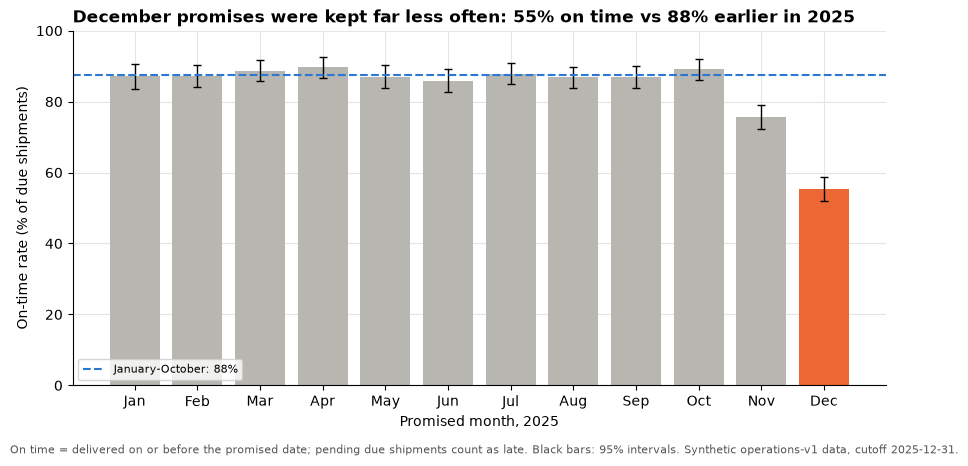

In [8]:
ci = pd.DataFrame([rate_ci(k, n) for k, n in zip(monthly["on_time"], monthly["due"])],
                  columns=["rate", "low", "high"], index=monthly.index)
x = np.arange(len(monthly))
colours = ["#eb6834" if m.month == 12 else "#b8b6b0" for m in monthly.index]

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(x, ci["rate"] * 100, color=colours)
ax.errorbar(x, ci["rate"] * 100, yerr=[(ci["rate"] - ci["low"]) * 100, (ci["high"] - ci["rate"]) * 100],
            fmt="none", ecolor="black", elinewidth=1, capsize=3)
ax.axhline(jan_oct_rate * 100, color="#2a78d6", linestyle="--", linewidth=1.5, label=f"January-October: {jan_oct_rate:.0%}")
ax.legend(fontsize=8, loc="lower left")
ax.set_xticks(x, monthly.index.strftime("%b"))
ax.set_ylim(0, 100)
ax.set_title(f"December promises were kept far less often: {december['rate']:.0%} on time "
             f"vs {jan_oct_rate:.0%} earlier in 2025")
ax.set_xlabel("Promised month, 2025")
ax.set_ylabel("On-time rate (% of due shipments)")
fig.text(0.01, -0.02, "On time = delivered on or before the promised date; pending due shipments count as late. "
         "Black bars: 95% intervals. Synthetic operations-v1 data, cutoff 2025-12-31.", fontsize=8, color="#555555")
fig.tight_layout()
plt.show()

Compare the figure above with a default chart of twelve equal bars. The orange bar, the dashed reference line and the title do the work; the intervals show that the earlier months are steady and December is clearly different. Everything else is grey.

> **Check your understanding 4**
>
> A colleague wants to add carrier, warehouse and service lines to this figure "so it is complete". What would you say, and where would that detail go instead?

---

## Part 6: One page, or three to five slides

Briefings are short by design. Two common formats:

| One-page brief | Three-to-five-slide briefing |
|---|---|
| **Title** = the recommendation as a sentence | **Slide 1**: the decision needed and your recommendation |
| **Recommendation** in two or three sentences, with owner and timing | **Slide 2**: the one summary figure, with a so-what title |
| **Why**: two or three findings, each with its number in context | **Slide 3**: trade-offs between the options, and why this one |
| **Trade-offs and risks** | **Slide 4**: uncertainty, limits and what would change your mind |
| **Uncertainty and limits** | **Slide 5**: next steps: owner, monitoring measure, review date |
| **Next steps** and **monitoring measure** | **Appendix**: definitions, checks, data versions, detailed tables |

For the capstone, the recommended flow is: decision requested → two or three evidence-backed findings → the cross-domain trade-off → recommended action and owner → monitoring measure and review period → limits and next evidence. Aim for about six minutes of talking and two minutes of questions. Keep metric definitions, checks and detailed slices in the appendix.

---

## Part 7: Handling questions and challenge

Questions are not attacks; they are the audience **testing whether to trust you**. Prepare for the predictable ones.

| Question | What a good answer contains |
|---|---|
| **"How do you know?"** | The definition, the check you ran and the data version: "on-time due shipments ÷ all due shipments; populations reconcile; operations-v1, cutoff 31 December" |
| **"What would change your mind?"** | Specific evidence: "If next month's ParcelOne rate returned to its earlier level with the same volume, the problem was a one-off" |
| **"Compared with what?"** | The baseline and why you chose it |
| **"Is this the cause?"** | Honest scope: "This shows where and when; to show why, we need..." |
| **"What happens if we wait?"** | The cost of delay, with its uncertainty |
| **"Why not option X instead?"** | The trade-off table and the weight-sensitivity result |
| **A question you cannot answer** | "I don't know. I can find out by [specific analysis] by [date]." Never guess a number |

The best preparation is an **appendix of ready answers**: small tables that answer the predictable follow-ups. For example, "Is it just one carrier?":

In [9]:
due["period"] = np.where(due["promised_month"] >= "2025-11-01", "Nov-Dec", "Jan-Oct")
answer = due.groupby(["carrier", "period"])["on_time"].agg(due="size", rate="mean").unstack("period")
answer.columns = [f"{measure} {period}" for measure, period in answer.columns]
answer[["due Jan-Oct", "rate Jan-Oct", "due Nov-Dec", "rate Nov-Dec"]].assign(
    **{c: lambda t, c=c: t[c].map("{:.0%}".format) for c in ["rate Jan-Oct", "rate Nov-Dec"]})

,due Jan-Oct,rate Jan-Oct,due Nov-Dec,rate Nov-Dec
carrier,,,,
ParcelOne,1546,84%,513,44%
Regional Express,947,89%,312,73%
SwiftRoute,1832,90%,592,77%


The table above lets you answer in one breath: every carrier's rate fell in the peak, but one fell much further. That is a more honest answer than either "yes, it is one carrier" or "no, it is everyone".

> **Check your understanding 5**
>
> An executive says: "Your numbers are wrong; our December was fine." Describe, in three steps, how you would respond without becoming defensive.

---

## Part 8: Common failure modes

| Failure | What it looks like | Fix |
|---|---|---|
| **Burying the lead** | The recommendation appears on the last slide | Recommendation in the first sentence |
| **Data dump** | Twelve charts "for completeness" | One summary figure; the rest in the appendix |
| **Naked numbers** | "60%" with no denominator, period or comparison | Number + denominator + period + comparison |
| **False precision** | "61.8421%" | Round for speech; exact figures in the appendix |
| **Hidden uncertainty** | A single number presented as certain | A range and the main assumptions |
| **Causal overreach** | "X caused Y" from descriptive data or co-movement | Say what the data show, and what would show causes |
| **False links** | Findings from separate datasets presented as one story | Keep each finding in its own context |
| **Defensive answers** | Arguing with the questioner | Acknowledge, show the evidence, offer a follow-up |
| **No ask** | Ends with "any questions?" | End with the decision you need and the next step |

---

## Part 9: The feedback rubric

Briefings and capstones are reviewed with a rubric of criteria and four levels. This **working rubric** is for **feedback**, so you know what strong work looks like; it is not an official grade. It includes a criterion for **statistical reasoning**: whether uncertainty, correlation versus causation and the choice of summaries are handled well.

| Criterion | 4: strong | 3: sound | 2: developing | 1: limited |
|---|---|---|---|---|
| **Decision framing and metric contracts** | Decision bounded; every metric's grain, period, filters and missing-value rule explicit | Clear decision; minor gaps in definitions | Broad decision or one important definition missing | No actionable decision; definitions missing |
| **Preparation and analytical correctness** | Grain and joins preserved; calculations reproducible | Core results correct; small non-critical issues | A join, date or denominator issue affects a result | Core results cannot be trusted |
| **Validation and reproducibility** | Versions, reconciliations, hand checks and corrected bugs complete | Critical checks done; minor gaps | Checks mostly visual or incomplete | Little usable validation |
| **Statistical reasoning** | Uncertainty quantified and explained; association kept separate from causation; right summary for each distribution | Uncertainty and causation handled with small gaps | Uncertainty ignored or one causal overclaim | Repeated overclaims; misleading summaries |
| **Visual communication** | One clear summary figure; so-what titles; labelled units; accessible colours | Clear figures with small labelling issues | A misleading encoding or missing context | Charts misrepresent the evidence |
| **Recommendation, synthesis and limitations** | Prioritised action with owner and monitoring; trade-offs and limits explicit; three or more domains without false links | Feasible action; synthesis and limits present | Action weakly linked to evidence; superficial synthesis | Unsupported recommendation; major overclaim |
| **Executive briefing** | Recommendation first; numbers in context; answers challenge with evidence | Clear briefing; competent answers | Overlong or unclear; weak answers | Cannot explain key results or assumptions |

The cell below turns the rubric into a scoring table. Each criterion has a weight; a criterion scores *weight × level ÷ 4*, so all level-4 scores give 100. The weights are a **teaching proposal** to show how a rubric combines criteria; your facilitator will tell you how feedback is used in your course.

In [10]:
rubric = pd.DataFrame({
    "weight": [15, 20, 15, 15, 10, 15, 10],
}, index=["Decision framing and metric contracts", "Preparation and analytical correctness",
          "Validation and reproducibility", "Statistical reasoning", "Visual communication",
          "Recommendation, synthesis and limitations", "Executive briefing"])
assert rubric["weight"].sum() == 100

example_levels = [3, 4, 3, 2, 3, 3, 4]          # an illustrative peer's levels, 1-4
scored = rubric.assign(level=example_levels, points=lambda t: t["weight"] * t["level"] / 4)
print(f"Total: {scored['points'].sum():.1f} of 100. Lowest-level criterion: {scored['level'].idxmin()}")
scored

Total: 78.8 of 100. Lowest-level criterion: Statistical reasoning


,weight,level,points
Decision framing and metric contracts,15,3,11.25
Preparation and analytical correctness,20,4,20.00
Validation and reproducibility,15,3,11.25
Statistical reasoning,15,2,7.50
Visual communication,10,3,7.50
"Recommendation, synthesis and limitations",15,3,11.25
Executive briefing,10,4,10.00


Read the scored table above the way a reviewer would: the **total** matters less than the **lowest criterion**, because that is where the next revision should start. A materially wrong critical number is never "averaged away": it must be corrected before the recommendation can be treated as verified.

---

## Part 10: Reflection and next steps

Over the Python sessions you have moved through the whole analytics workflow:

| Stage | What you can now do |
|---|---|
| **Question** | Turn a request into a decision, population, period and measure |
| **Data** | Check grain, keys, types and missing values; clean and log changes |
| **Measure** | Define metrics with contracts; use ratios of sums; avoid the classic traps |
| **Describe and relate** | Summarise distributions, trends and relationships, and know what correlation cannot show |
| **Quantify uncertainty** | Build confidence intervals and read an A/B test honestly |
| **Apply** | Analyse retail, finance, operations, marketing and HR cases under their contracts |
| **Communicate** | Build dashboards, write so-what titles, brief executives and handle challenge |

**What comes next: the Tableau section.** The course continues by rebuilding key analyses in Tableau, using the same datasets and the same metric contracts. Everything in this lecture carries over: a Tableau dashboard needs the same so-what titles, context and honesty about uncertainty. See the [course roadmap](../course/roadmap.md).

### Reflection

Answer these for yourself; your lab's course reflection builds on them.

1. Which **one** trap from the course (for example, the mean of rates, the current-headcount denominator, dropped pending shipments, a false join) are you most likely to meet at work? How will you spot it?
2. Which **check** will you now run on every analysis before you share it?
3. Think of a decision at your own workplace. What would its evidence register contain, and which domain would be hardest to measure?
4. What would you do differently if you started your capstone again?

---

## Summary

| Question | Tool | Trap to avoid |
|---|---|---|
| What do I say first? | The recommendation, as an action | Opening with data and method |
| How do I organise the argument? | Pyramid: message → reasons → evidence | A chronological story of the work |
| What goes in a title? | A so-what sentence built from the data | A topic label |
| How do I state a number? | Denominator, period, comparison, unit, rounding | Naked numbers; false precision |
| How sure am I? | A range or interval, plus assumptions, in plain words | Hiding uncertainty; "95% probability" wording |
| How do I handle challenge? | Prepared appendix answers; "what would change my mind" | Guessing, arguing, or causal overreach |
| How is a briefing judged? | A rubric with levels, including statistical reasoning | Treating a total as more important than the weakest criterion |

---

## Lab briefing

In the **Lab** you:

1. Turn a provided operations analysis into a one-page brief and a single summary figure.
2. Prepare your own capstone briefing: structure, figure and an anticipated-questions table.
3. Critique a peer's briefing with the rubric, and write a revision plan.
4. Challenge: answer three tough executive questions in writing, with evidence.
5. Finish with an exit ticket and a course reflection.

Open the [Session 16 lab](16_executive_briefings_lab.md).